In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(r'D:\Nikss\Self Pracitce\Deep learning\39 Day 39 - Pine Indians Diabetes Dataset.csv')

In [3]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
df.corr()['Outcome']

Pregnancies                 0.221898
Glucose                     0.466581
BloodPressure               0.065068
SkinThickness               0.074752
Insulin                     0.130548
BMI                         0.292695
DiabetesPedigreeFunction    0.173844
Age                         0.238356
Outcome                     1.000000
Name: Outcome, dtype: float64

In [5]:
x = df.iloc[:, 0 : -1]
y = df.drop(x, axis = 'columns')

In [6]:
x.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148,72,35,0,33.6,0.627,50
1,1,85,66,29,0,26.6,0.351,31
2,8,183,64,0,0,23.3,0.672,32
3,1,89,66,23,94,28.1,0.167,21
4,0,137,40,35,168,43.1,2.288,33


In [7]:
y.head()

,Outcome
0,1
1,0
2,1
3,0
4,1


In [8]:
# train test split

from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 1) 

In [9]:
# Scaling

from sklearn.preprocessing import StandardScaler

ss = StandardScaler()

x_train_scaled = ss.fit_transform(x_train)
x_test_scaled = ss.transform(x_test)

In [10]:
x_train_scaled[0:5]

array([[ 1.51659096,  0.75052361,  0.56475624,  1.65201535,  0.43749607,
         0.79582546,  0.52952571,  0.56793202],
       [ 1.81201827,  0.24475163, -0.34790438,  1.02097303, -0.67847404,
         1.22865369, -0.06968859,  0.39844951],
       [ 0.92573636, -0.60873859,  0.26053603,  1.27338996,  0.22288644,
         0.70401341, -0.79424873,  0.99163829],
       [ 1.22116366, -0.03974511,  0.46334951, -1.25077932, -0.67847404,
        -0.89613942, -0.16751949,  2.60172212],
       [-0.55140014, -0.03974511,  0.36194277,  1.08407726,  0.22288644,
         1.03191358, -0.76061935, -0.36422177]])

In [11]:
x_train.shape

(614, 8)

In [12]:
import tensorflow as tf
from tensorflow import keras
from keras.layers import Dense, Dropout
from keras.models import Sequential

In [13]:
model1 = Sequential()

model1.add(Dense(32, activation = 'relu', input_dim = 8))
model1.add(Dense(1, activation = 'sigmoid'))

model1.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 32)                288       
                                                                 
 dense_1 (Dense)             (None, 1)                 33        
                                                                 
Total params: 321 (1.25 KB)
Trainable params: 321 (1.25 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [14]:
model1.compile(loss = 'binary_crossentropy', optimizer = 'adam', metrics = ['accuracy'])

In [15]:
history1 = model1.fit(x_train_scaled, y_train, batch_size = 32, epochs = 10, validation_data = (x_test_scaled, y_test))

Epoch 1/10
20/20 [==============================] - 1s 13ms/step - loss: 0.6336 - accuracy: 0.6775 - val_loss: 0.6032 - val_accuracy: 0.7078
Epoch 2/10
20/20 [==============================] - 0s 5ms/step - loss: 0.5870 - accuracy: 0.7199 - val_loss: 0.5701 - val_accuracy: 0.7403
Epoch 3/10
20/20 [==============================] - 0s 4ms/step - loss: 0.5546 - accuracy: 0.7329 - val_loss: 0.5466 - val_accuracy: 0.7597
Epoch 4/10
20/20 [==============================] - 0s 7ms/step - loss: 0.5314 - accuracy: 0.7410 - val_loss: 0.5274 - val_accuracy: 0.7662
Epoch 5/10
20/20 [==============================] - 0s 5ms/step - loss: 0.5136 - accuracy: 0.7573 - val_loss: 0.5141 - val_accuracy: 0.7727
Epoch 6/10
20/20 [==============================] - 0s 5ms/step - loss: 0.5007 - accuracy: 0.7622 - val_loss: 0.5045 - val_accuracy: 0.7597
Epoch 7/10
20/20 [==============================] - 0s 6ms/step - loss: 0.4904 - accuracy: 0.7687 - val_loss: 0.4961 - val_accuracy: 0.7597
Epoch 8/10
20/20 [=

# Step 1: How to select appropriate optimizer

In [16]:
import kerastuner as kt

C:\Users\jugal\AppData\Local\Temp\ipykernel_31560\1654478174.py:1: DeprecationWarning: `import kerastuner` is deprecated, please use `import keras_tuner`.
  import kerastuner as kt


The process is like this, first of all we create a function where we define our model and then we pass that
function to a tuner object.

In [17]:
def build_model(hp):    # hp stands for hyperparameter

    model = Sequential()

    model.add(Dense(32, activation = 'relu', input_dim = 8))
    # Here, we are not concerned for no_of nodes. We're learning for best optimizer.
    model.add(Dense(1, activation = 'sigmoid'))

    optimizer = hp.Choice('optimizer', values = ['adam', 'sgd', 'rmsprop', 'adadelta', 'nadam']) # 'optimizer' is nothing just a string
    model.compile(optimizer = optimizer, loss = 'binary_crossentropy', metrics = ['accuracy'])

    return model

# Here we have given 5 different optimizers. So, this will create 4 different models each with one optimizer.

In [18]:
# Making a tuner object

tuner = kt.RandomSearch(build_model, objective = 'val_accuracy', max_trials = 5, directory = 'my_dir', project_name = 'best_optimizer')

# build_model: It's our UDF we just created
# objective: According to the value, decides whether to reduce or increase(here, val_acc, so, increase)
# max_trials: Specifies the total number of different hyperparameter combinations that will be tested during the search.

In [19]:
tuner.search(x_train_scaled, y_train, epochs = 5, validation_data = (x_test_scaled, y_test))

Trial 5 Complete [00h 00m 02s]
val_accuracy: 0.7662337422370911

Best val_accuracy So Far: 0.7727272510528564
Total elapsed time: 00h 00m 10s


In [20]:
# get the best optimizer

tuner.get_best_hyperparameters()[0].values

{'optimizer': 'nadam'}

In [21]:
# Get the best model

model = tuner.get_best_models(num_models = 1)[0]
# We have 5 models for 5 optimizers, but we want the best model, so, num_models = 1.
# If, num_models = 3, will give 3 top best models

In [22]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 32)                288       
                                                                 
 dense_1 (Dense)             (None, 1)                 33        
                                                                 
Total params: 321 (1.25 KB)
Trainable params: 321 (1.25 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [23]:
model.compile(optimizer = 'rmsprop', loss = 'binary_crossentropy', metrics = ['accuracy'])

In [24]:
history = model.fit(x_train_scaled, y_train, batch_size = 32, epochs = 100, initial_epoch = 6, validation_data = (x_test_scaled, y_test))

Epoch 7/100
20/20 [==============================] - 1s 17ms/step - loss: 0.5365 - accuracy: 0.7524 - val_loss: 0.5197 - val_accuracy: 0.7792
Epoch 8/100
20/20 [==============================] - 0s 4ms/step - loss: 0.5182 - accuracy: 0.7557 - val_loss: 0.5089 - val_accuracy: 0.7727
Epoch 9/100
20/20 [==============================] - 0s 4ms/step - loss: 0.5069 - accuracy: 0.7606 - val_loss: 0.5005 - val_accuracy: 0.7792
Epoch 10/100
20/20 [==============================] - 0s 4ms/step - loss: 0.4979 - accuracy: 0.7671 - val_loss: 0.4936 - val_accuracy: 0.7792
Epoch 11/100
20/20 [==============================] - 0s 4ms/step - loss: 0.4907 - accuracy: 0.7720 - val_loss: 0.4885 - val_accuracy: 0.7792
Epoch 12/100
20/20 [==============================] - 0s 4ms/step - loss: 0.4847 - accuracy: 0.7736 - val_loss: 0.4858 - val_accuracy: 0.7922
Epoch 13/100
20/20 [==============================] - 0s 4ms/step - loss: 0.4799 - accuracy: 0.7720 - val_loss: 0.4830 - val_accuracy: 0.7922
Epoch 14

In [25]:
import matplotlib.pyplot as plt

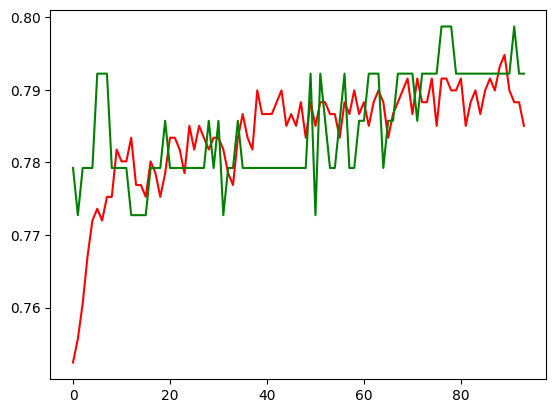

In [26]:
plt.plot(history.history['accuracy'], color = 'red')
plt.plot(history.history['val_accuracy'], color = 'green')


# 2) How to select appropriate no_of neurons for each layer

In [27]:
def build_model(hp):

    model = Sequential()

    nodes = hp.Int('nodes', min_value = 8, max_value = 256)    
    # nodes is just a string, can pass any name
    # 8 to 256 with step 8 means it takes random value between 8 to 256

    model.add(Dense(units = nodes, activation = 'relu', input_dim = 8))
    model.add(Dense(1, activation = 'sigmoid'))

    model.compile(loss = 'binary_crossentropy', optimizer = 'rmsprop', metrics = ['accuracy'])    # Now we know that rmsprop is the best optimizer

    return model

In [28]:
tuner = kt.RandomSearch(build_model, objective = ['val_accuracy'], max_trials = 5, directory = 'mydir', project_name = 'no_of_nodes')

In [29]:
tuner.search(x_train_scaled, y_train, epochs = 5, validation_data = (x_test_scaled, y_test))

Trial 5 Complete [00h 00m 02s]
multi_objective: -0.7792207598686218

Best multi_objective So Far: -0.8246753215789795
Total elapsed time: 00h 00m 09s


In [30]:
tuner.get_best_hyperparameters()[0].values

# This is the best no_of nodes we should keep

{'nodes': 121}

In [31]:
# Getting the best model

model = tuner.get_best_models(num_models = 1)[0]

# This will give us the model with 184 nodes

In [32]:
history2 = model.fit(x_train_scaled, y_train, batch_size = 32, epochs = 100, initial_epoch = 6, validation_data = (x_test_scaled, y_test))

Epoch 7/100
20/20 [==============================] - 1s 15ms/step - loss: 0.4727 - accuracy: 0.7704 - val_loss: 0.4696 - val_accuracy: 0.7987
Epoch 8/100
20/20 [==============================] - 0s 5ms/step - loss: 0.4661 - accuracy: 0.7752 - val_loss: 0.4669 - val_accuracy: 0.7987
Epoch 9/100
20/20 [==============================] - 0s 4ms/step - loss: 0.4611 - accuracy: 0.7769 - val_loss: 0.4654 - val_accuracy: 0.7792
Epoch 10/100
20/20 [==============================] - 0s 4ms/step - loss: 0.4570 - accuracy: 0.7785 - val_loss: 0.4637 - val_accuracy: 0.7857
Epoch 11/100
20/20 [==============================] - 0s 5ms/step - loss: 0.4553 - accuracy: 0.7818 - val_loss: 0.4621 - val_accuracy: 0.7792
Epoch 12/100
20/20 [==============================] - 0s 5ms/step - loss: 0.4527 - accuracy: 0.7785 - val_loss: 0.4619 - val_accuracy: 0.7792
Epoch 13/100
20/20 [==============================] - 0s 4ms/step - loss: 0.4501 - accuracy: 0.7769 - val_loss: 0.4598 - val_accuracy: 0.7857
Epoch 14

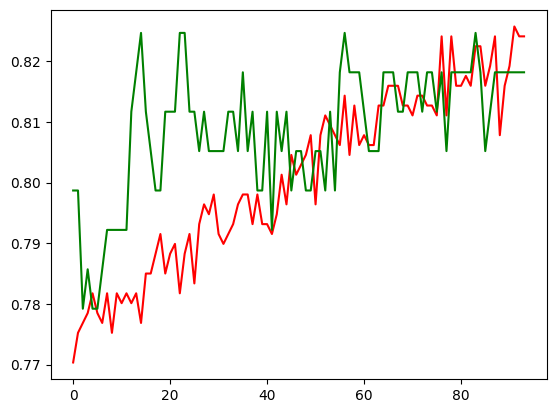

In [33]:
plt.plot(history2.history['accuracy'], color = 'red')
plt.plot(history2.history['val_accuracy'], color = 'green')

# 3) Select optimum no_of hidden layers

In [34]:
def build_model(hp):

    model = Sequential()

    model.add(Dense(210, activation = 'relu', input_dim = 8))    # Input layer

    for i in range(hp.Int('no_of_layers', min_value = 1, max_value = 10)):    # Loop will select the best no_of hidden layers

        model.add(Dense(210, activation = 'relu',))

    model.add(Dense(1, activation = 'sigmoid'))    # Output layer

    model.compile(loss = 'binary_crossentropy', optimizer = 'rmsprop', metrics = ['accuracy'])

    return model

In [35]:
tuner = kt.RandomSearch(build_model,
                       objective = 'val_accuracy',
                       max_trials = 5, directory = 'my__dir',
                       project_name = 'no_of_hidden_layers')

In [36]:
tuner.search(x_train_scaled, y_train, validation_data = (x_test_scaled, y_test), epochs = 5)

Trial 5 Complete [00h 00m 02s]
val_accuracy: 0.8116883039474487

Best val_accuracy So Far: 0.8116883039474487
Total elapsed time: 00h 00m 13s


In [37]:
tuner.get_best_hyperparameters()[0].values

{'no_of_layers': 6}

In [38]:
model = tuner.get_best_models(num_models = 1)[0]

history3 = model.fit(x_train_scaled, y_train, validation_data = (x_test_scaled, y_test), epochs = 100, initial_epoch = 6)

Epoch 7/100
20/20 [==============================] - 1s 21ms/step - loss: 0.4575 - accuracy: 0.7720 - val_loss: 0.5111 - val_accuracy: 0.7727
Epoch 8/100
20/20 [==============================] - 0s 7ms/step - loss: 0.4469 - accuracy: 0.7899 - val_loss: 0.4857 - val_accuracy: 0.7727
Epoch 9/100
20/20 [==============================] - 0s 7ms/step - loss: 0.4216 - accuracy: 0.7948 - val_loss: 0.7536 - val_accuracy: 0.7403
Epoch 10/100
20/20 [==============================] - 0s 7ms/step - loss: 0.4236 - accuracy: 0.8078 - val_loss: 0.4767 - val_accuracy: 0.7727
Epoch 11/100
20/20 [==============================] - 0s 7ms/step - loss: 0.4054 - accuracy: 0.8208 - val_loss: 0.4900 - val_accuracy: 0.7922
Epoch 12/100
20/20 [==============================] - 0s 8ms/step - loss: 0.3960 - accuracy: 0.8062 - val_loss: 0.5377 - val_accuracy: 0.7273
Epoch 13/100
20/20 [==============================] - 0s 6ms/step - loss: 0.3976 - accuracy: 0.8192 - val_loss: 0.5637 - val_accuracy: 0.7727
Epoch 14

# 4) Applying everything what we learnt.

In [39]:

def build_model(hp):

    model = Sequential()

    counter = 0

    for i in range(hp.Int('no_of_layers', min_value = 1, max_value = 10)):
        
        if counter == 0:

            model.add(
                Dense(
                    hp.Int('no_of_nodes' + str(i), min_value = 8, max_value = 128, step = 8),
                    activation = hp.Choice('activation' + str(i), values = ['relu', 'tanh', 'sigmoid']),
                    input_dim = 8
                )
            )

        else:
            model.add(
                Dense(
                    hp.Int('no_of_nodes' + str(i), min_value = 8, max_value = 128, step = 8),
                    activation = hp.Choice('activation' + str(i), values = ['relu', 'tanh', 'sigmoid'])
                )
            )

        counter += 1
        
    model.add(Dense(1, activation = 'sigmoid'))

    model.compile(
        loss = 'binary_crossentropy',
        optimizer = hp.Choice('optimizer', values = ['adam', 'nadam', 'rmsprop', 'sgd', 'adadelta']),
        metrics = ['accuracy']
    )
    return model

In [40]:
tuner = kt.RandomSearch(build_model, 
                        objective = 'val_accuracy',
                        max_trials = 5,
                        directory = 'my_dir4',
                        project_name = 'everything_together')

In [41]:
tuner.search(x_train_scaled, y_train, validation_data = (x_test_scaled, y_test), epochs = 5)

Trial 5 Complete [00h 00m 03s]
val_accuracy: 0.7662337422370911

Best val_accuracy So Far: 0.8181818127632141
Total elapsed time: 00h 00m 16s


In [42]:
tuner.get_best_hyperparameters()[0].values

{'no_of_layers': 7,
 'no_of_nodes0': 104,
 'activation0': 'relu',
 'optimizer': 'rmsprop',
 'no_of_nodes1': 16,
 'activation1': 'relu',
 'no_of_nodes2': 112,
 'activation2': 'tanh',
 'no_of_nodes3': 24,
 'activation3': 'tanh',
 'no_of_nodes4': 128,
 'activation4': 'tanh',
 'no_of_nodes5': 96,
 'activation5': 'sigmoid',
 'no_of_nodes6': 88,
 'activation6': 'relu',
 'no_of_nodes7': 8,
 'activation7': 'sigmoid',
 'no_of_nodes8': 40,
 'activation8': 'tanh'}

In [43]:
model = tuner.get_best_models(num_models = 1)[0]

In [44]:
history4 = model.fit(x_train_scaled, y_train, validation_data = (x_test_scaled, y_test), epochs = 100, initial_epoch = 5)

Epoch 6/100
20/20 [==============================] - 2s 18ms/step - loss: 0.4578 - accuracy: 0.7850 - val_loss: 0.4459 - val_accuracy: 0.8182
Epoch 7/100
20/20 [==============================] - 0s 5ms/step - loss: 0.4491 - accuracy: 0.7850 - val_loss: 0.4608 - val_accuracy: 0.8117
Epoch 8/100
20/20 [==============================] - 0s 5ms/step - loss: 0.4455 - accuracy: 0.7932 - val_loss: 0.5742 - val_accuracy: 0.7403
Epoch 9/100
20/20 [==============================] - 0s 4ms/step - loss: 0.4439 - accuracy: 0.7915 - val_loss: 0.4659 - val_accuracy: 0.7727
Epoch 10/100
20/20 [==============================] - 0s 5ms/step - loss: 0.4344 - accuracy: 0.8046 - val_loss: 0.4790 - val_accuracy: 0.7792
Epoch 11/100
20/20 [==============================] - 0s 5ms/step - loss: 0.4238 - accuracy: 0.8094 - val_loss: 0.5282 - val_accuracy: 0.7727
Epoch 12/100
20/20 [==============================] - 0s 5ms/step - loss: 0.4280 - accuracy: 0.8094 - val_loss: 0.4642 - val_accuracy: 0.7922
Epoch 13/

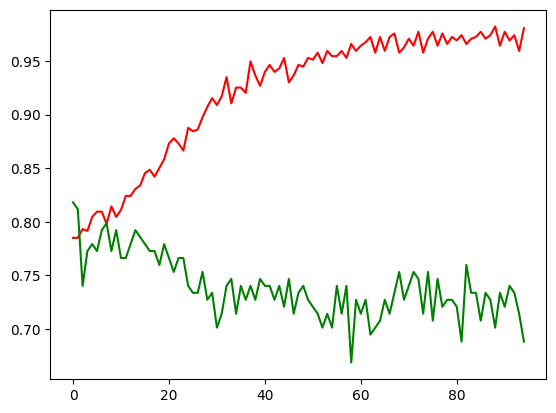

In [45]:
plt.plot(history4.history['accuracy'], color = 'red')
plt.plot(history4.history['val_accuracy'], color = 'green')

# Let's also add dropout layer as well

In [46]:
def build_model(hp):

    model = Sequential()

    counter = 0

    no_of_layers = hp.Int('No_of_layers', min_value = 1, max_value = 10)
    optimizers = hp.Choice('Optimizer ', values = ['adam', 'nadam', 'rmsprop', 'adadelta', 'sgd'])

    for i in range(no_of_layers):

        nodes = hp.Int('No_of_nodes_ ' + str(i), min_value = 1, max_value = 128, step = 8)
        activation = hp.Choice('activation_ ' + str(i), values = ['relu', 'tanh', 'sigmoid'])
        
        if counter == 0:
            model.add(Dense(units = nodes,
                     activation = activation,
                     input_dim = 8))
           
            model.add(Dropout(hp.Choice('Dropout ' + str(i), values = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])))  # Dense layer

        else:
            model.add(Dense(units = nodes,
                     activation = activation))
            
            model.add(Dropout(hp.Choice('Dropout ' + str(i), values = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])))  # Dense layer
        counter += 1
    
    model.add(Dense(1, activation = 'sigmoid'))

    model.compile(loss = 'binary_crossentropy', optimizer = optimizers, metrics = ['accuracy'])

    return model

In [47]:
tuner = kt.RandomSearch(build_model, 
                        max_trials = 5, 
                        objective = 'val_accuracy',
                        directory = 'my_dir4',
                        project_name = 'Tuning with dropout layer')

In [48]:
tuner.search(x_train_scaled, y_train, validation_data = (x_test_scaled, y_test), epochs = 5)

Trial 5 Complete [00h 00m 04s]
val_accuracy: 0.8051947951316833

Best val_accuracy So Far: 0.8051947951316833
Total elapsed time: 00h 00m 13s


In [49]:
tuner.get_best_hyperparameters()[0].values

{'No_of_layers': 4,
 'Optimizer ': 'nadam',
 'No_of_nodes_ 0': 89,
 'activation_ 0': 'tanh',
 'Dropout 0': 0.1,
 'No_of_nodes_ 1': 97,
 'activation_ 1': 'tanh',
 'Dropout 1': 0.3,
 'No_of_nodes_ 2': 65,
 'activation_ 2': 'sigmoid',
 'Dropout 2': 0.6,
 'No_of_nodes_ 3': 57,
 'activation_ 3': 'tanh',
 'Dropout 3': 0.6,
 'No_of_nodes_ 4': 41,
 'activation_ 4': 'tanh',
 'Dropout 4': 0.6,
 'No_of_nodes_ 5': 113,
 'activation_ 5': 'relu',
 'Dropout 5': 0.4,
 'No_of_nodes_ 6': 97,
 'activation_ 6': 'tanh',
 'Dropout 6': 0.9}

In [51]:
model = tuner.get_best_models(num_models = 1)[0]

history5 = model.fit(x_train_scaled, y_train, validation_data = (x_test_scaled, y_test), epochs = 200, initial_epoch = 5)

Epoch 6/200
20/20 [==============================] - 2s 14ms/step - loss: 0.5941 - accuracy: 0.7231 - val_loss: 0.4634 - val_accuracy: 0.7922
Epoch 7/200
20/20 [==============================] - 0s 5ms/step - loss: 0.6092 - accuracy: 0.6971 - val_loss: 0.4665 - val_accuracy: 0.7987
Epoch 8/200
20/20 [==============================] - 0s 5ms/step - loss: 0.5329 - accuracy: 0.7280 - val_loss: 0.4742 - val_accuracy: 0.7922
Epoch 9/200
20/20 [==============================] - 0s 5ms/step - loss: 0.5197 - accuracy: 0.7638 - val_loss: 0.4726 - val_accuracy: 0.8117
Epoch 10/200
20/20 [==============================] - 0s 6ms/step - loss: 0.5302 - accuracy: 0.7736 - val_loss: 0.4753 - val_accuracy: 0.7922
Epoch 11/200
20/20 [==============================] - 0s 7ms/step - loss: 0.5572 - accuracy: 0.7280 - val_loss: 0.4730 - val_accuracy: 0.8052
Epoch 12/200
20/20 [==============================] - 0s 7ms/step - loss: 0.5674 - accuracy: 0.7248 - val_loss: 0.4735 - val_accuracy: 0.7987
Epoch 13/

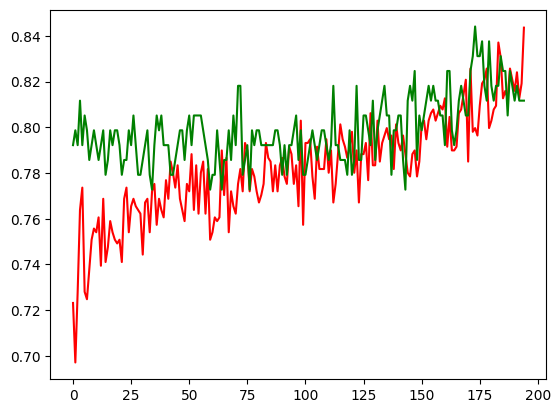

In [52]:
plt.plot(history5.history['accuracy'], color = 'red')
plt.plot(history5.history['val_accuracy'], color = 'green')

In [53]:
# Applying earlystopping as well

In [55]:
from keras.callbacks import EarlyStopping

In [74]:
earlystopping = EarlyStopping(
    monitor = 'val_accuracy',
    min_delta = 0.00001,
    patience = 5,
    verbose = 1
)

In [57]:
def build_model(hp):

    model = Sequential()

    counter = 0

    no_of_layers = hp.Int('No_of_layers', min_value = 1, max_value = 10)
    optimizers = hp.Choice('Optimizer ', values = ['adam', 'nadam', 'rmsprop', 'adadelta', 'sgd'])

    for i in range(no_of_layers):

        nodes = hp.Int('No_of_nodes_ ' + str(i), min_value = 1, max_value = 128, step = 8)
        activation = hp.Choice('activation_ ' + str(i), values = ['relu', 'tanh', 'sigmoid'])
        
        if counter == 0:
            model.add(Dense(units = nodes,
                     activation = activation,
                     input_dim = 8))
           
            model.add(Dropout(hp.Choice('Dropout ' + str(i), values = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])))  # Dense layer

        else:
            model.add(Dense(units = nodes,
                     activation = activation))
            
            model.add(Dropout(hp.Choice('Dropout ' + str(i), values = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])))  # Dense layer
        counter += 1
    
    model.add(Dense(1, activation = 'sigmoid'))

    model.compile(loss = 'binary_crossentropy', optimizer = optimizers, metrics = ['accuracy'])

    return model

In [58]:
tuner = kt.RandomSearch(build_model,
                       max_trials = 5,
                       objective = 'val_accuracy',
                       directory = 'my_dir4',
                       project_name = 'Tunning with EarlyStopping')

In [60]:
tuner.search(x_train_scaled, y_train, validation_data = (x_test_scaled, y_test), epochs = 5)

Trial 5 Complete [00h 00m 03s]
val_accuracy: 0.6428571343421936

Best val_accuracy So Far: 0.7662337422370911
Total elapsed time: 00h 00m 16s


In [61]:
tuner.get_best_hyperparameters()[0].values

{'No_of_layers': 2,
 'Optimizer ': 'nadam',
 'No_of_nodes_ 0': 81,
 'activation_ 0': 'tanh',
 'Dropout 0': 0.7,
 'No_of_nodes_ 1': 1,
 'activation_ 1': 'relu',
 'Dropout 1': 0.1}

In [62]:
model = tuner.get_best_models(num_models = 1)[0]

In [75]:
history6 = model.fit(x_train_scaled, y_train, validation_data = (x_test_scaled, y_test), epochs = 200, initial_epoch = 5,
                     callbacks = earlystopping)

Epoch 6/200
20/20 [==============================] - 0s 6ms/step - loss: 0.5333 - accuracy: 0.7557 - val_loss: 0.5017 - val_accuracy: 0.7922
Epoch 7/200
20/20 [==============================] - 0s 5ms/step - loss: 0.5527 - accuracy: 0.7476 - val_loss: 0.5020 - val_accuracy: 0.7922
Epoch 8/200
20/20 [==============================] - 0s 7ms/step - loss: 0.5435 - accuracy: 0.7508 - val_loss: 0.5018 - val_accuracy: 0.7857
Epoch 9/200
20/20 [==============================] - 0s 7ms/step - loss: 0.5501 - accuracy: 0.7427 - val_loss: 0.4983 - val_accuracy: 0.7922
Epoch 10/200
20/20 [==============================] - 0s 5ms/step - loss: 0.5371 - accuracy: 0.7671 - val_loss: 0.4960 - val_accuracy: 0.7922
Epoch 11/200
20/20 [==============================] - 0s 4ms/step - loss: 0.5151 - accuracy: 0.7671 - val_loss: 0.4946 - val_accuracy: 0.7857
Epoch 11: early stopping


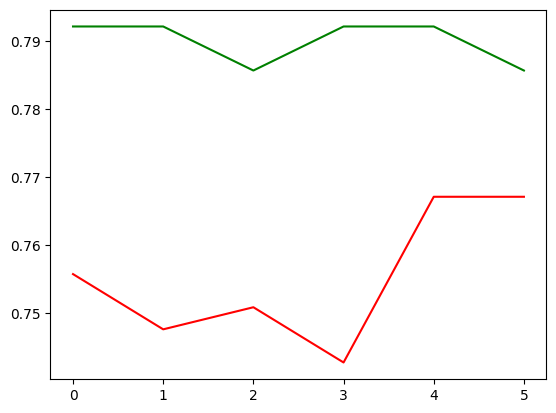

In [76]:
plt.plot(history6.history['accuracy'], color = 'red')
plt.plot(history6.history['val_accuracy'], color = 'green')

# Here, we have completed our ANN part. Next we'll start `Convolution Neural Network`

# `Next Session:` Day 40 - Intro to CNN